## Real Estate Analysis (ZIP 90004)
Credentials come from .env 

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv("../.env")
engine = create_engine(f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
                       f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT','5432')}/{os.getenv('DB_NAME')}?sslmode=require")


df=pd.read_sql("select * from student_project.properties_cleaned",engine)
print(df.shape)
df.head()

(119, 14)


,property_id,status,list_date,list_price,amount_reduced,city,state,postal_code,bedrooms,bathrooms,property_sqft,property_type,is_outlier,price_per_sqft
0,1000618972,for_sale,2026-09-01,759000,0.0,Los Angeles,California,90004,2,2.0,1087.0,condos,False,698.25
1,1010818622,for_sale,2025-11-21,1245000,302000.0,Los Angeles,California,90004,4,3.0,3088.0,multi_family,False,403.17
2,1059792398,for_sale,2026-08-28,3000000,0.0,Malibu,California,90004,0,0.0,0.0,land,False,0.00
3,1141459809,for_sale,2026-09-25,3400000,0.0,Los Angeles,California,90004,0,32.0,18604.0,multi_family,False,182.76
4,1266324287,for_sale,2026-11-03,1375000,0.0,Los Angeles,California,90004,11,6.0,4103.0,multi_family,True,335.12


# How do price vary by property type

In [9]:
summary=(df.groupby("property_type")["list_price"]
         .agg(listing="count",average="mean",median="median")
         .round(0).sort_values("median",ascending=False))
summary

,listing,average,median
property_type,,,
land,8,2030500.0,1975000.0
multi_family,45,2744744.0,1925000.0
single_family,48,3078467.0,1724500.0
townhomes,1,1048000.0,1048000.0
condos,17,861000.0,735000.0


<function matplotlib.pyplot.show(close=None, block=None)>

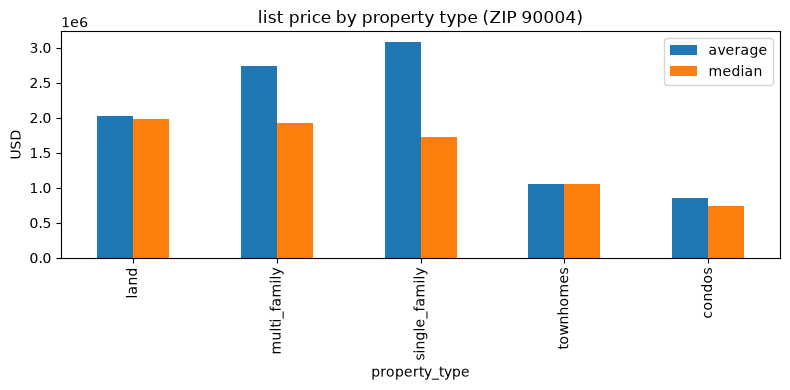

In [10]:
ax=summary[["average","median"]].plot(kind="bar",figsize=(8,4))
ax.set_title("list price by property type (ZIP 90004)")
ax.set_ylabel("USD")
plt.tight_layout()
plt.show

FINDINGS:In ZIP 90004,single_family($3.17M average)and multi_family($2.60M average)properties command the highest average list prices,while condos are the most affordable at an $861k average ($759k median).Notably,single-family and multi-family averages are substantially higher than their medians (~$1.89M and $1.84M),indicating high-end luxury outliers pulling the mean upward,whereas townhomes reflect only a single listing ($1.05M).

## Price tiers

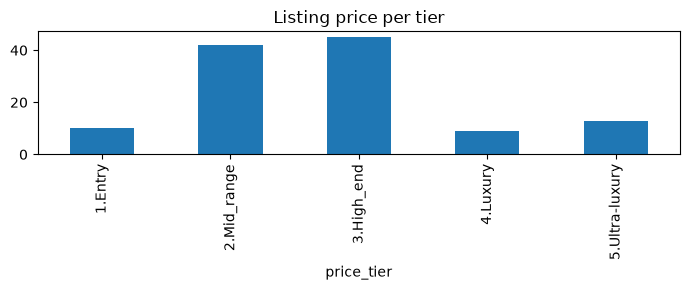

price_tier
1.Entry           10
2.Mid_range       42
3.High_end        45
4.Luxury           9
5.Ultra-luxury    13
Name: count, dtype: int64

In [11]:
bins=[0,750_000,1_500_000,3_500_000,5_000_000,float("inf")]
labels=["1.Entry","2.Mid_range","3.High_end","4.Luxury","5.Ultra-luxury"]
df["price_tier"]=pd.cut(df["list_price"],bins=bins,labels=labels,right=False)
tiers=df["price_tier"].value_counts().sort_index()
tiers.plot(kind="bar",figsize=(7,3),title="Listing price per tier")
plt.tight_layout();plt.show()
tiers

CONCLUSION: Most listings fall into the High-end (45 listings) and Mid-range (42 listings) tiers, while Luxury has the fewest (9 listings), followed closely by Entry (10 listings) and Ultra-luxury (13 listings). This shows that the market is concentrated in the middle-to-upper-middle price range rather than entry-level or luxury homes.

3.Most expensive listing

In [12]:
df.sort_values("list_price",ascending=False).head(5)[["property_type","property_id","list_price","price_tier"]]

,property_type,property_id,list_price,price_tier
31,single_family,2066418083,19995000,5.Ultra-luxury
28,single_family,2045325560,17495000,5.Ultra-luxury
21,single_family,1993302304,9995000,5.Ultra-luxury
73,multi_family,2191557118,7950000,5.Ultra-luxury
91,multi_family,2255027927,7500000,5.Ultra-luxury


4.Outliers

In [13]:
print(df["is_outlier"].sum(),"outliers listings")
df.groupby("is_outlier")["list_price"].agg(["count","mean","median"]).round(0)

25 outliers listings


,count,mean,median
is_outlier,,,
False,94,1893988.0,1467500.0
True,25,5006960.0,3500000.0


Finding: The 25 outlier listings have a much higher average price ($5.01M) than the remaining 94 listings ($1.89M), which pulls the overall market average up. As a result, the median ($1.47M for non-outliers) gives a more accurate picture of typical home prices than the overall average.

In [14]:
import os
os.makedirs("../powerbi",exist_ok=True)
df.to_csv("../powerbi/powerbi_data.csv",index=False)